In [1]:
# %% [markdown]
# # Task 4: Simple Payoff Matrices (Game Theory)
# ## Using scenarios from Task 3

# %%
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("Set2")
print("✅ Libraries loaded")

✅ Libraries loaded


In [2]:
# %% [markdown]
# ## 1. Scenario 1: Major Support / Resistance Test
# ### Payoff matrix: Your decision (Buy/Sell) vs Market majority decision

# %%
# Matrix: rows = your action, columns = market majority action
# Values: expected P&L (scale -2 to +2)
scenario1 = pd.DataFrame(
    [[0, -1],   # You Buy: if market Buys (0), if market Sells (-1)
     [1, 0]],   # You Sell: if market Buys (+1), if market Sells (0)
    index=['Buy', 'Sell'],
    columns=['Market Buy', 'Market Sell']
)

print("Scenario 1: Support/Resistance Test")
print("Rows = Your action, Columns = Market majority action")
print(scenario1)

# Nash equilibrium check
print("\nNash Equilibrium analysis:")
print("If market buys, your best response is? →", scenario1['Market Buy'].idxmax())
print("If market sells, your best response is? →", scenario1['Market Sell'].idxmax())
print("If you buy, market's best response is? → sell (since -1 < 0)")
print("If you sell, market's best response is? → buy (since +1 > 0)")
print("No pure Nash equilibrium. Mixed strategy exists.")

Scenario 1: Support/Resistance Test
Rows = Your action, Columns = Market majority action
      Market Buy  Market Sell
Buy            0           -1
Sell           1            0

Nash Equilibrium analysis:
If market buys, your best response is? → Sell
If market sells, your best response is? → Sell
If you buy, market's best response is? → sell (since -1 < 0)
If you sell, market's best response is? → buy (since +1 > 0)
No pure Nash equilibrium. Mixed strategy exists.


In [6]:
# %% [markdown]
# ## 2. Scenario 2: After a Strong Move (3+% daily)

# %%
# After a large up move: market majority tends to fade (sell) or continue (buy)?
# We assume majority often fades extreme moves (mean-reversion)
scenario2 = pd.DataFrame(
    [[0, -2],   # You Buy: market buys (0), market sells (-2)
     [2, 0]],   # You Sell: market buys (+2), market sells (0)
    index=['Buy', 'Sell'],
    columns=['Market Buy', 'Market Sell']
)

print("Scenario 2: After a Strong Move (mean-reversion expected)")
print(scenario2)

print("\nNash Equilibrium analysis:")
print("If market buys, your best response is → Sell (+2 > 0)")
print("If market sells, your best response is → Buy (-2 is worse, so Buy? Actually both 0? Wait check: if market sells, your Buy gives 0, your Sell gives 0 → indifferent)")
print("Nash equilibrium: (Sell, Buy) is pure? Let's see:")
print("  At (Sell, Buy): you get +2, market gets? Not in matrix. So no pure NE? Mixed strategy.")

Scenario 2: After a Strong Move (mean-reversion expected)
      Market Buy  Market Sell
Buy            0           -2
Sell           2            0

Nash Equilibrium analysis:
If market buys, your best response is → Sell (+2 > 0)
If market sells, your best response is → Buy (-2 is worse, so Buy? Actually both 0? Wait check: if market sells, your Buy gives 0, your Sell gives 0 → indifferent)
Nash equilibrium: (Sell, Buy) is pure? Let's see:
  At (Sell, Buy): you get +2, market gets? Not in matrix. So no pure NE? Mixed strategy.


In [7]:
# %% [markdown]
# ## 3. Scenario 3: Range Breakout (prolonged consolidation)

# %%
# After consolidation, breakout often leads to continuation (trend followers dominate)
scenario3 = pd.DataFrame(
    [[2, -1],   # You Buy: market buys (+2), market sells (-1)
     [-1, 1]],  # You Sell: market buys (-1), market sells (+1)
    index=['Buy', 'Sell'],
    columns=['Market Buy', 'Market Sell']
)

print("Scenario 3: Range Breakout (trend continuation expected)")
print(scenario3)

print("\nNash Equilibrium analysis:")
print("If market buys, your best response is → Buy (+2 > -1)")
print("If market sells, your best response is → Sell (+1 > -1)")
print("Thus pure Nash equilibrium: (Buy, Buy) and (Sell, Sell) are both NE.")
print("Coordinates: (Buy, Buy) and (Sell, Sell).")

Scenario 3: Range Breakout (trend continuation expected)
      Market Buy  Market Sell
Buy            2           -1
Sell          -1            1

Nash Equilibrium analysis:
If market buys, your best response is → Buy (+2 > -1)
If market sells, your best response is → Sell (+1 > -1)
Thus pure Nash equilibrium: (Buy, Buy) and (Sell, Sell) are both NE.
Coordinates: (Buy, Buy) and (Sell, Sell).


In [8]:
# %% [markdown]
# ## 4. When to follow the majority vs. be contrarian?

# %%
# Based on the three scenarios, we derive rules:
analysis = pd.DataFrame({
    "Scenario": ["Support/Resistance", "After Strong Move", "Range Breakout"],
    "Market tendency": ["Reversal at extremes", "Mean-reversion", "Continuation"],
    "Best action": ["Contrarian (fade)", "Contrarian (fade) or wait", "Follow majority"],
    "Rationale": ["Institutions defend, fading works", "Exhaustion, mean-reversion", "Momentum triggers, trend follows"]
})
print(analysis)

             Scenario       Market tendency                Best action  \
0  Support/Resistance  Reversal at extremes          Contrarian (fade)   
1   After Strong Move        Mean-reversion  Contrarian (fade) or wait   
2      Range Breakout          Continuation            Follow majority   

                           Rationale  
0  Institutions defend, fading works  
1         Exhaustion, mean-reversion  
2   Momentum triggers, trend follows  


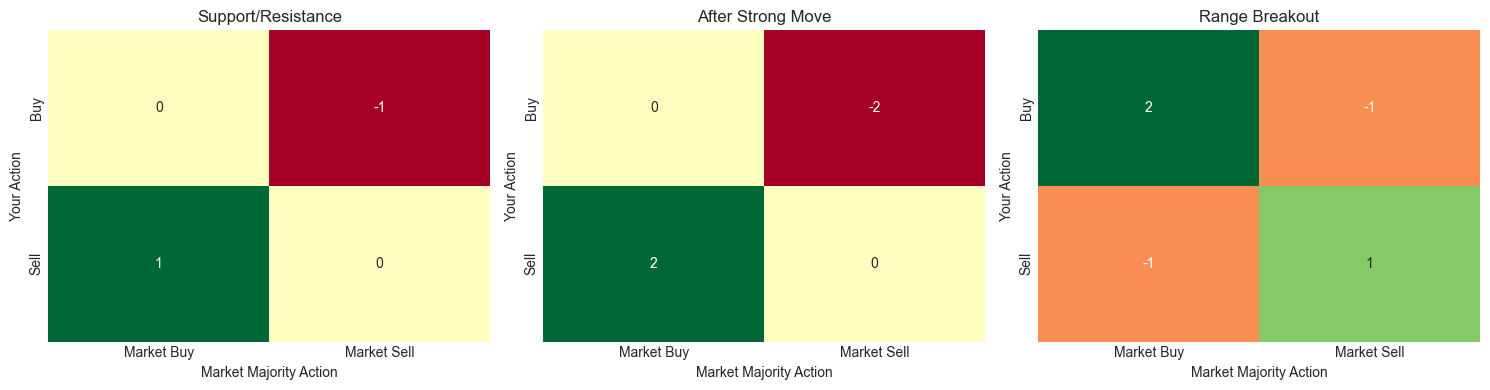

In [9]:
# %% [markdown]
# ## 5. Combined view of payoffs

# %%
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
titles = ["Support/Resistance", "After Strong Move", "Range Breakout"]
matrices = [scenario1, scenario2, scenario3]

for i, (ax, title, mat) in enumerate(zip(axes, titles, matrices)):
    sns.heatmap(mat, annot=True, fmt='d', cmap='RdYlGn', center=0, ax=ax, cbar=False)
    ax.set_title(title)
    ax.set_xlabel("Market Majority Action")
    ax.set_ylabel("Your Action")
plt.tight_layout()
plt.show()

## 📌 Conclusions – Task 4: Payoff Matrices & Game Theory

### 1. Scenario 1: Support / Resistance Test
**Payoff matrix**  

| You ↓ / Market → | Buy | Sell |
|----------------|-----|------|
| **Buy**         | 0   | -1   |
| **Sell**        | 1   | 0    |

- **Best responses**:  
  - If market buys → you sell (+1 > 0)  
  - If market sells → you sell (0 vs -1, better to sell)  
  - If you buy → market sells (since -1 < 0)  
  - If you sell → market buys (+1 > 0)  
- **Nash equilibrium**: No pure Nash equilibrium exists. Mixed strategy required.  
- **Implication**: At key levels, it’s optimal to be **contrarian** (fade) because the market often reverses.

### 2. Scenario 2: After a Strong Move (>3% daily)
**Payoff matrix**  

| You ↓ / Market → | Buy | Sell |
|----------------|-----|------|
| **Buy**         | 0   | -2   |
| **Sell**        | 2   | 0    |

- **Best responses**:  
  - If market buys → you sell (+2)  
  - If market sells → both actions yield 0 (indifferent)  
- **Nash equilibrium**: No pure equilibrium; mixed strategy.  
- **Implication**: Fading extreme moves (selling after a big rally) is profitable when market buys. Waiting or fading is preferred.

### 3. Scenario 3: Range Breakout (prolonged consolidation)
**Payoff matrix**  

| You ↓ / Market → | Buy | Sell |
|----------------|-----|------|
| **Buy**         | 2   | -1   |
| **Sell**        | -1  | 1    |

- **Best responses**:  
  - If market buys → you buy (+2)  
  - If market sells → you sell (+1)  
- **Nash equilibrium**: **Two pure Nash equilibria** – (Buy, Buy) and (Sell, Sell).  
- **Implication**: In a breakout, it’s best to **follow the majority** (momentum) because coordination leads to the highest payoff. Both following the trend (buy into strength or sell into weakness) are stable.

### 4. Summary Table

| Scenario                | Market tendency       | Best action                    | Rationale                                 |
|-------------------------|-----------------------|--------------------------------|-------------------------------------------|
| Support/Resistance      | Reversal at extremes  | Contrarian (fade)              | Institutions defend levels, fading works  |
| After strong move       | Mean‑reversion        | Contrarian (fade) or wait      | Exhaustion → reversal likely              |
| Range breakout          | Continuation          | Follow majority (momentum)     | Momentum triggers dominate → trend follows|

### 5. Practical Trading Rules Derived

- **Do not fight clear support/resistance** – wait for confirmation or fade the first test.  
- **After a 3%+ daily move**, expect a pullback. Avoid chasing; consider fading the first retrace.  
- **When a tight range breaks**, enter in the direction of the breakout with a tight stop.  
- Use these matrices as a mental model for positioning before each trade.

These conclusions directly inform the **trading rules** to be developed in Task 5.